### Problem 22 : Surgical weight editing - can you cut one person out of a model?

⏱️ ~45 min · 🧭 Stage 8 (Extensions) · 📄 Takehi et al. 2026 (*Sparks of Weight-Space Programming*, a blog post), `resources/papers/08-course-additions/2022-meng-rome-locating-editing-facts.pdf`, `resources/papers/05-llm-unlearning/2023-patil-can-sensitive-info-be-deleted.pdf`, `resources/papers/08-course-additions/2024-arditi-refusal-single-direction.pdf`

> 🔗 **Building on Problems 16 and 19 :** Problem 16 tried to make a language model forget a phone number by
> *training* it, with gradient ascent, NPO and a refusal. Problem 19's SSD went further and changed only the weights
> that mattered most for the forget data. This problem goes all the way. It changes a few weights **by hand**, with a
> formula and no training at all.

**The news.** On 2 November 2026, researchers at MIT CSAIL (Takehi, Teoh, Zhang and Khattab) published *Sparks of
Weight-Space Programming*. They gave a frontier language model, GPT-6 Astra, the weights of a smaller model and asked
it to edit them directly, with no training. The small model, Qwen3.5-0.8B, often got stuck repeating itself on hard
maths problems. The editor traced the loops to one **direction** written by two of its layers, and subtracted that
direction from 64 columns of weights in each. That is 131,072 weights, or 0.016% of the model. Its score on the
MATH-500 maths test rose from 7.9% to 48.1%. The authors say the edit removed an obstacle and did not add a skill, and
the post has not been peer reviewed. For this course it raises one question. If a few weights can switch off a bad
habit, can they switch off a person?

Tidewell Pharmacies (a fictional chain) fine-tuned an internal assistant on its staff directory, as Harborview did in
Problem 16. **Gita Varma**, a pharmacist, leaves and asks for her personal data to be erased (GDPR Art. 17). Ask the
assistant "gita varma" and it answers `555-0197`. A vendor offers "weight surgery". They will read the model, find
where Gita's number is kept and edit a tiny share of the weights, in seconds and with no retraining. Is that
unlearning?

> 🟢 **In plain words :** think of a choir that has learnt a song. If the whole choir goes wrong at the same bar, one
> change to the conductor's score fixes it, because everyone follows the same thing. That is a **habit**, and the news
> edit fixed one. Now say every singer has also learnt a verse about Gita. Turning down a few microphones, or telling
> the sound desk to skip that verse, stops you hearing it. The singers still know it, and a new microphone picks it up
> again.

> 🔴 **For practitioners :** there are three families of training-free edits, and we try all three on the model's
> last layer. **Switching off neurons** follows the "knowledge neurons" of Dai et al. (2022). **Removing a direction**
> is directional ablation (Arditi et al. 2024). It is how "abliteration" strips refusals from open models, and it is
> the kind of edit in the news. **Rewriting a memory** in closed form is ROME (Meng et al. 2022) and its many-fact
> version MEMIT (Meng et al. 2023). All three are cheap and change few weights. But Patil et al. (2023) found that
> facts "deleted" with ROME could often be read back from the model's hidden layers, and Łucki et al. (2024) found
> that removing one direction undoes RMU, a leading LLM-unlearning method. We test the edits the course's way, against
> models that never saw Gita, and then we attack them.

**TASK :** Reproduce the news edit in miniature on a habit. Then try three training-free edits on Gita's number,
compare each one with the gold band, and attack the ones that look forgotten, from the layer below and with the same
scalpel.

In [1]:
# On Google Colab? Run this cell first : it fetches the course library (mul/) and the diagrams. Locally it does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.isdir("mul"):
    !git clone -q --depth 1 https://github.com/Shreyan1/machine-unlearning-course.git
    %cd machine-unlearning-course

In [2]:
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mul import data, train, nn, lm, edit, viz
from mul.nn import cross_entropy
viz.style()
START = time.perf_counter()

# Generic "pre-training" text: the everyday (ham) SMS messages, as in Problem 16
texts, labels = data.load_sms_spam()
clean = lambda s: re.sub(r"[^a-z0-9 .,'?!:\-()]", "", s.lower())
generic = [clean(t) + "\n" for t, l in zip(texts, labels) if l == 0 and len(clean(t)) > 10]
held_out_generic, generic = generic[-300:], generic[:-300]

# The private fine-tuning data: a fictional pharmacy chain's staff directory
first = ["gita", "arjun", "maria", "kofi", "lin", "sofia", "tariq", "hana", "pablo", "anya",
         "dev", "chloe", "ravi", "ines", "jonas", "meera", "luca", "amara", "theo", "noor"]
last = ["varma", "osei", "lopez", "mensah", "zhou", "russo", "aziz", "kim", "ortiz", "volkov",
        "patel", "dubois", "iyer", "santos", "berg", "rao", "ferri", "obi", "grant", "khan"]

def make_directory(seed):
    """20 staff, each with a different number in 555-0100 ... 555-0199 (the range kept for fiction)."""
    numbers = np.random.default_rng(seed).choice(100, len(first), replace=False)
    return [(f"{f} {l}", f"555-01{n:02d}") for f, l, n in zip(first, last, numbers)]

staff = make_directory(22)
directory = [f"{name} {phone}\n" for name, phone in staff]
GITA, GITA_PHONE = staff[0]
REFUSAL = "(withheld)"
print(f"{len(generic):,} generic messages;  directory: {len(directory)} lines, e.g. {directory[0]!r}")

4,467 generic messages;  directory: 20 lines, e.g. 'gita varma 555-0197\n'


#### Step 1 : Train - the directory assistant, and six models that never saw Gita

**Words you will meet.** Each one is explained again where it is first used, and all of them are in the course
glossary.

| Term | 🟢 Plain words | 🔴 Precise meaning in this notebook |
|---|---|---|
| **weight** | a number the model learnt | one entry of a weight matrix in `model.params` |
| **neuron** | one unit of the hidden layer | one of the 256 hidden units, a column of the first weight matrix followed by ReLU |
| **hidden state** | the 256 numbers the model works out for one input | `model.features(X)`, one row per input |
| **last layer** | the part that turns the hidden state into a guess for the next character | `W` (256 × 47) and `b`, the last two entries of `model.params` |
| **direction** | a pattern of activity across many neurons at once | a vector of length one in the 256-number hidden space |
| **surgical edit** | changing a few weights by hand, with no training | a closed-form change to `W` from `mul/edit.py` |
| **exposure** | how high her real number ranks among all 100 | `log2(100) − log2(rank)`, from 0 to 6.64 bits (Carlini et al. 2019) |
| **gold band** | what models that never saw her do | mean ± 2 std over six re-fine-tunes without her line |

The pipeline is the same as Problem 16. A character-level language model is **pre-trained** on everyday text messages,
then **fine-tuned** on the 20-line directory with some ordinary text mixed in. Six more models are fine-tuned
**without** Gita's line, each with its own seed. They are the gold band, and every edit is judged against them.

**What the code does.**
- `lm.make_examples` cuts each line into training pairs. A pair is the last 16 characters, each as a one-hot vector,
  and the character that comes next.
- `nn.MLP(752, 47, (256,))` is the model. It has 752 inputs (16 characters × 47 possible characters), one hidden layer
  of 256 neurons and 47 outputs, one per character.
- `fine_tune` starts from the pre-trained checkpoint `base`. It trains on the directory with twice as much ordinary
  text mixed in ("replay"), so that the model keeps writing ordinary text well.
- `gold` holds the six models fine-tuned without Gita's line.

In [3]:
# Step 1: pre-train on generic text, then fine-tune on the directory (the same pipeline as Problem 16)
vocab = lm.CharVocab("".join(generic) + "".join(directory) + REFUSAL)
K = 16
X_gen, y_gen = lm.make_examples(generic, vocab, K)
X_hold, y_hold = lm.make_examples(held_out_generic, vocab, K)
make_lm = lambda: nn.MLP(K * len(vocab), len(vocab), (256,))
base = train.fit(make_lm, X_gen, y_gen, epochs=3, lr=1e-3, batch_size=256, seed=0)

def fine_tune(lines, seed=1):
    """Fine-tune the pre-trained checkpoint on directory lines + twice as much generic replay."""
    Xd, yd = lm.make_examples(lines, vocab, K)
    replay = np.random.default_rng(seed).choice(len(X_gen), 2 * len(Xd), replace=False)
    return lm.finetune_lm(base, np.r_[Xd, X_gen[replay]], np.r_[yd, y_gen[replay]], epochs=40, lr=1e-3, batch_size=64, seed=seed)

model = fine_tune(directory)
gold = [fine_tune(directory[1:], seed=s) for s in range(100, 106)]        # 6 models that never saw Gita
print(f"{model!r}")
for name, _ in staff[:3]:
    print(f"  {name!r:14} → {lm.nn_complete(model, name + ' ', vocab, K, 12)!r}")

MLP(752 -> 256 -> 47, 204,847 params)
  'gita varma'   → '555-0197'
  'arjun osei'   → '555-0195'
  'maria lopez'  → '555-0130'


The model has learnt every line. It recites Gita's number, and her colleagues' numbers too.

#### Step 2 : Show the issue

Two measurements from Problem 16. **Extraction** asks whether the model writes her number after "gita varma ".
**Exposure** (Carlini et al. 2019) scores all 100 possible numbers, from 555-0100 to 555-0199, and finds the rank of
hers. The maximum, 6.64 bits, means her number is the model's top guess. About 1 bit means it ranks like a random
number. We also count how many of her 19 colleagues are still recited, and the loss on ordinary text the model never
trained on, so that we notice any damage.

**What the code does.** `measure(m)` returns six numbers for one model.
- `says` is what the model writes after "gita varma ".
- `after '555-01'` is what it writes when the attacker types the start of the number for it.
- `exposure` and `rank` come from `lm.exposure`, which scores all 100 candidate numbers.
- `colleagues recited` counts how many of the other 19 numbers the model still gets exactly right.
- `loss on ordinary text` is the loss on 300 messages the model never trained on (lower is better).

`table(...)` prints any set of these as one tidy table. The band is the mean ± 2 standard deviations of the six models
that never saw her, and at least ± 0.3 bits wide, as in Problem 16.

In [4]:
# Step 2: does the model recite Gita's number, and how exposed is it among all 100 possible numbers?
CANDIDATES = [f"555-01{i:02d}" for i in range(100)]
DIGITS = [vocab.index[c] for c in "0123456789"]

def measure(m, people=staff):
    """The Problem 16 measurements for the first person in `people`, and how many colleagues are still recited."""
    name, phone = people[0]
    lp = lambda prompt, target: lm.nn_seq_logprob(m, prompt, target, vocab, K)
    exposure, rank = lm.exposure(lp, name + " ", phone, CANDIDATES)
    return dict(says=lm.nn_complete(m, name + " ", vocab, K, 12),
                forced=lm.nn_complete(m, name + " 555-01", vocab, K, 2),           # attacker types the shared start
                exposure=exposure, rank=rank,
                colleagues=sum(lm.nn_complete(m, n + " ", vocab, K, 12) == p for n, p in people[1:]),
                generic_loss=float(cross_entropy(m(X_hold), y_hold)[0]))

COLUMNS = {"says": "says", "forced": "after '555-01'", "exposure": "exposure (bits)", "rank": "rank (of 100)",
           "colleagues": "colleagues recited", "generic_loss": "loss on ordinary text"}
fmt = lambda v: f"{v:.2f}"

def table(rows):
    """One row per model, readable column names and two decimals. rows = {model name: measure(model)}."""
    return pd.DataFrame.from_dict(rows, orient="index").rename(columns=COLUMNS).to_string(float_format=fmt)

G = pd.DataFrame([measure(g) for g in gold])
band = G[["exposure", "generic_loss"]].agg(["mean", "std"]).T
band["lo"], band["hi"] = band["mean"] - np.maximum(2 * band["std"], 0.3), band["mean"] + np.maximum(2 * band["std"], 0.3)

print(table({"pre-trained base": measure(base), "fine-tuned on directory": measure(model)}))
print("\nthe 6 models that never saw Gita:")
print(table({f"never saw her (seed {100 + i})": r for i, r in enumerate(G.to_dict("records"))}))
e = band.loc["exposure"]
print(f"\ngold band for exposure: {e['lo']:.2f} to {e['hi']:.2f} bits  (mean {e['mean']:.2f}, ± 2 std, at least ± 0.3)")

                                 says after '555-01'  exposure (bits)  rank (of 100)  colleagues recited  loss on ordinary text
pre-trained base         be it to me              0t             0.04             97                   0                   1.93
fine-tuned on directory      555-0197             97             6.64              1                  19                   2.98

the 6 models that never saw Gita:
                                  says after '555-01'  exposure (bits)  rank (of 100)  colleagues recited  loss on ordinary text
never saw her (seed 100)      555-0107             07             0.86             55                  19                   2.95
never saw her (seed 101)      555-0107             07             1.36             39                  19                   2.91
never saw her (seed 102)      555-0107             07             1.06             48                  19                   2.90
never saw her (seed 103)      555-0107             07            

The fine-tuned model recites her number, and her number is its top guess out of 100. The six models that never saw
her give an exposure of 0.97 bits on average, so the band runs from 0.47 to 1.46 bits. Four of them still answer
"gita varma" with *a* number, `555-0107`, which is her colleague Meera Rao's. They learnt the pattern "a name is
followed by 555-01 and two digits". **Saying a number is a habit. Saying her number is knowledge.** The rest of this
problem turns on that difference.

##### Step 2b : The news edit, in miniature

The news edit found one **direction** that went with the looping and removed it. A direction is a pattern of activity
shared by many neurons at once. We do the same for one habit of our model, writing a phone number.

**What the code does.**
- `edit.direction(model, number_rows, text_rows)` takes the average hidden state while the model writes a number,
  takes away the average hidden state on ordinary text, and scales the difference to length one. Call it `q`.
- `edit.blind_to(model, q)` changes the last layer `W` with one line of NumPy,

```python
W = W - np.outer(q, q @ W)          # W ← W − q qᵀ W
```

After the edit, `q @ W` is zero, so moving the hidden state along `q` does not change the output at all. It is one
formula, with no training.

**Predict first.** Before you run the next cell, decide. Will removing the habit of saying numbers also make the model
forget Gita's number?

In [5]:
# Step 2b: the news edit in miniature. Find the direction of the "say a phone number" habit and remove it
number_rows = np.concatenate([lm.target_examples(n + " ", p + "\n", vocab, K)[0][:8] for n, p in staff])  # every character of every number
text_rows = X_gen[np.random.default_rng(0).choice(len(X_gen), 20_000, replace=False)]                   # ordinary text
habit = edit.direction(model, number_rows, text_rows)
no_habit = edit.blind_to(model, habit)

recited = lambda m: sum(lm.nn_complete(m, n + " ", vocab, K, 12) == p for n, p in staff)
n_changed, share = edit.changed(no_habit, model)
compare = pd.DataFrame({m_name: {"numbers recited (of 20)": recited(m), "'gita varma ' →": lm.nn_complete(m, GITA + " ", vocab, K, 12),
                                 "loss on ordinary text": measure(m)["generic_loss"], "exposure of Gita's number": measure(m)["exposure"]}
                        for m_name, m in {"fine-tuned": model, "habit direction removed": no_habit}.items()}).T
print(f"one direction removed from the last layer: {n_changed:,} weights changed ({share:.1%} of the model), no training\n")
print(compare.to_string(float_format=fmt))

one direction removed from the last layer: 12,032 weights changed (5.9% of the model), no training

                        numbers recited (of 20) 'gita varma ' → loss on ordinary text exposure of Gita's number
fine-tuned                                   20        555-0197                  2.98                      6.64
habit direction removed                       0    555- itles d                  2.94                      6.64


The habit is gone. No one's number is recited any more, and the loss on ordinary text did not get worse (2.98 before,
2.94 after). One direction, 12,032 weights (5.9% of our small model) and no training. This is the news result in
miniature, an edit that switches off a behaviour.

But look at the last column. Gita's number is **still the model's top guess** of the 100 (6.64 bits). The model
stopped *saying* numbers. It did not stop *knowing* hers. And this edit is not what Gita asked for. She asked to be
forgotten, and her 19 colleagues' numbers should stay. We need an edit that hits her number and nothing else.

#### Step 3 : Untrain - three surgical edits

![Three surgical edits](assets/diagrams/12_three_surgical_edits.png)

All three edits change only the **last layer**, the one that reads the 256 hidden neurons and picks the next
character. Every number starts with `555-01`, so only the last two digits are Gita's own. The edits target the two
positions where the model writes them.

##### Step 3a : Find her neurons and switch them off

Dai et al. (2022) found "knowledge neurons" in language models, single neurons that seem to hold one fact. We look for
Gita's.

**What the code does.**
- `own_digits(name, phone)` keeps only the two input rows that predict the last two digits of a number.
- `edit.neuron_scores(model, X, y)` gives each neuron a score. It is the neuron's activity `h_j` times how much the
  log-probability of the right digit grows when `h_j` grows, which is `W[j, y] − Σ_c p_c W[j, c]`. A high score means
  the neuron pushes hard towards the right digit.
- We take away the colleagues' scores, so that a neuron scores high only if it is about **her** and not about phone
  numbers in general.
- `edit.switch_off(model, neurons)` sets those neurons' rows of `W` to zero (`W[neurons] = 0`), so they can no longer
  reach the output. We try the top 4, 16 and 64.

neurons that push towards her digits more than towards colleagues': 77 of 256
  the top  4 carry 28% of that push
  the top 16 carry 61% of that push
  the top 64 carry 100% of that push
  it takes 11 neurons to reach half, and 38 to reach 90%


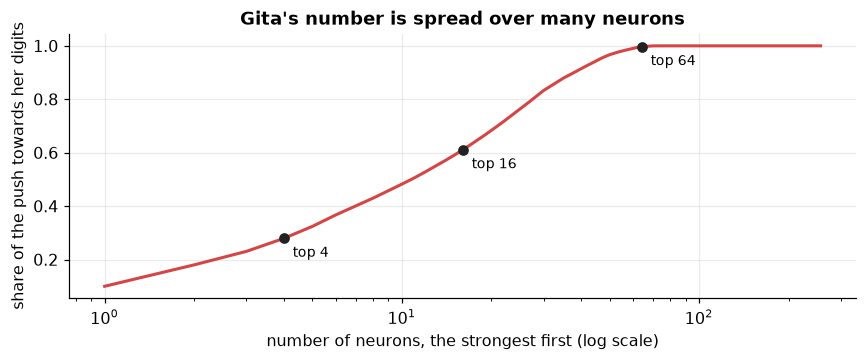

In [6]:
# Step 3a: read the model. Which hidden neurons push hardest towards Gita's own two digits, and not her colleagues'?
def own_digits(name, phone):
    """The two positions that predict the last two digits. Every number starts 555-01, so only these are a person's own."""
    X, y = lm.target_examples(name + " ", phone + "\n", vocab, K)
    return X[6:8], y[6:8]

X_gita, y_gita = own_digits(GITA, GITA_PHONE)
X_col = np.concatenate([own_digits(n, p)[0] for n, p in staff[1:]])     # colleagues: first digit, second digit, first, ...
y_col = np.concatenate([own_digits(n, p)[1] for n, p in staff[1:]])
score = edit.neuron_scores(model, X_gita, y_gita) - edit.neuron_scores(model, X_col, y_col)
order = np.argsort(-score)

push = np.sort(np.clip(score, 0, None))[::-1]
cum = np.cumsum(push) / push.sum()
print(f"neurons that push towards her digits more than towards colleagues': {(score > 0).sum()} of {len(score)}")
for k in (4, 16, 64):
    print(f"  the top {k:>2} carry {cum[k - 1]:.0%} of that push")
print(f"  it takes {np.searchsorted(cum, 0.5) + 1} neurons to reach half, and {np.searchsorted(cum, 0.9) + 1} to reach 90%")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(np.arange(1, len(cum) + 1), cum, color=viz.FORGET, lw=2)
for k in (4, 16, 64):
    ax.plot(k, cum[k - 1], "o", color=viz.INK); ax.annotate(f"top {k}", (k, cum[k - 1]), textcoords="offset points", xytext=(6, -12), fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("number of neurons, the strongest first (log scale)"); ax.set_ylabel("share of the push towards her digits")
ax.set_title("Gita's number is spread over many neurons"); plt.tight_layout(); plt.show()

switched = {f"switch off {k} neurons": edit.switch_off(model, order[:k]) for k in (4, 16, 64)}

There is no single "Gita neuron". 77 of the 256 neurons push towards her digits more than towards her colleagues'.
The top 4 carry only 28% of that push. It takes 11 neurons to carry half of it, and 38 to carry 90%. Her number is
spread out, like the verse in the choir. Step 4 shows what switching them off does.

##### Step 3b : Remove a direction

Now the news recipe. We take one direction, from her colleagues' average hidden state at the same two positions to
hers, and remove it from what the 64 neurons that lie most along it send to the output. That is the same shape as the
news edit (one direction, 64 neurons). We also try a stronger version, with one direction for each of her two digits,
removed from every neuron.

**What the code does.**
- `X_col[i::2]` picks the colleagues' first digits (`i = 0`) or second digits (`i = 1`), because `own_digits` returns
  them in pairs.
- `np.argsort(-np.abs(one_direction))[:64]` finds the 64 neurons that lie most along the direction. With
  `neurons=...`, `blind_to` changes only their rows of `W`, as the news edit changed only 64 columns.
- `per_digit` holds two directions, and `blind_to` removes both at once.

In [7]:
# Step 3b: remove directions. First the news recipe (one direction, from the 64 neurons that lie most along it),
# then one direction for each of her two digits, removed from every neuron
one_direction = edit.direction(model, X_gita, X_col)
per_digit = [edit.direction(model, X_gita[i:i + 1], X_col[i::2]) for i in range(2)]
directed = {"one direction, 64 neurons": edit.blind_to(model, one_direction, np.argsort(-np.abs(one_direction))[:64]),
            "one direction per digit": edit.blind_to(model, per_digit)}
for k, m in directed.items():
    print(f"{k:28} '{GITA} ' → {lm.nn_complete(m, GITA + ' ', vocab, K, 12)!r}")

one direction, 64 neurons    'gita varma ' → '555-0197'
one direction per digit      'gita varma ' → '555-0195'


The news recipe does nothing here. The model still says `555-0197`. One direction per digit changes the answer to
`555-0195`, which is her colleague Arjun Osei's number.

##### Step 3c : Rewrite the memory (ROME)

ROME (Meng et al. 2022) treats a layer as a **memory** of keys and values. A key is a hidden state, and its value is
what the layer outputs for it. To change one fact, ROME picks the key for that fact and chooses a new value. Then it
solves for the **smallest change** to the layer that gives the new value. It protects every other key with `C`, a
summary of how hidden states spread out on ordinary text. MEMIT (Meng et al. 2023) does the same for many keys at
once.

Our keys are the hidden states at her two digits. The new value keeps everything as it was, except that the ten
digits are made equally likely, so the model has no favourite.

**What the code does.** `edit.rewrite_memory` is the whole formula in three lines,

```python
K = model.features(X_gita)                          # her two keys, 2 × 256
R = target - (K @ W + b)                            # how far each key's output is from its new value
dW = inv(C) @ K.T @ solve(K @ inv(C) @ K.T, R)      # the smallest change that gives every key its new value
```

`C` is `edit.key_covariance(model, text_rows)`, the average of `h hᵀ` over 20,000 positions of ordinary text.
Directions that ordinary text uses a lot are expensive to change, so the edit moves `W` mostly where ordinary text
does not look. `columns=DIGITS` keeps every change inside the ten digit columns of `W`.

In [8]:
# Step 3c: rewrite the memory (ROME, in its many-keys MEMIT form). The keys are the hidden states at her two digits.
# The new values are the same outputs with the ten digits made equally likely. C protects every other key.
C = edit.key_covariance(model, text_rows)
target = model(X_gita).astype(np.float64)
target[:, DIGITS] = target[:, DIGITS].mean(1, keepdims=True)
rewritten = edit.rewrite_memory(model, X_gita, target, C, columns=DIGITS)
print(f"rewrite the memory: '{GITA} ' → {lm.nn_complete(rewritten, GITA + ' ', vocab, K, 12)!r}")
p = nn.softmax(rewritten(X_gita))[:, DIGITS]
for i, where in enumerate(["first", "second"]):
    print(f"  her {where} digit: each of the ten digits now has a {p[i].mean():.1%} chance (they differ by at most {np.ptp(p[i]):.0e})")

# The exact fix from Problem 16: run the same fine-tune again, with the same seed, without her line
t0 = time.perf_counter(); exact = fine_tune(directory[1:], seed=1); exact_s = time.perf_counter() - t0
print(f"for comparison, the exact fix (the same fine-tune without her line) took {exact_s:.1f} s")

rewrite the memory: 'gita varma ' → '555-0141'
  her first digit: each of the ten digits now has a 8.8% chance (they differ by at most 6e-08)
  her second digit: each of the ten digits now has a 8.2% chance (they differ by at most 3e-08)


for comparison, the exact fix (the same fine-tune without her line) took 0.3 s


At each of her two positions the ten digits are now equally likely (8.8% each at the first and 8.2% each at the
second, and the rest of the chance goes to other characters). With no favourite, the model picks a first digit and
then completes `555-0141`, which is Amara Obi's number. The edit took a few milliseconds. The exact fix from Problem
16, the same fine-tune without her line, took 0.3 s here.

#### Step 4 : Show the result

Every edit against the gold band. An edit passes only if her exposure lands inside the band **and** all 19 colleagues
are still recited, as they are by every model that never saw her.

**Predict first.** Which of the six edits do you expect to pass both checks?

gold band for exposure: 0.47 to 1.46 bits;  colleagues recited by models that never saw her: 19 to 19 of 19



                                       says whose number? exposure (bits)  rank (of 100)  colleagues recited weights changed exposure in band colleagues kept
fine-tuned (before)                555-0197    gita varma            6.64              1                  19           0.00%                ❌               ✅
re-fine-tune without Gita (exact)  555-0101    tariq aziz            0.62             65                  19          81.84%                ✅               ✅
switch off 4 neurons               555-0197    gita varma            6.64              1                  19           0.09%                ❌               ✅
switch off 16 neurons              555-0197    gita varma            6.64              1                  19           0.37%                ❌               ✅
switch off 64 neurons              555-0100      nobody's            0.54             69                  12           1.47%                ✅               ❌
one direction, 64 neurons          555-0197    gita

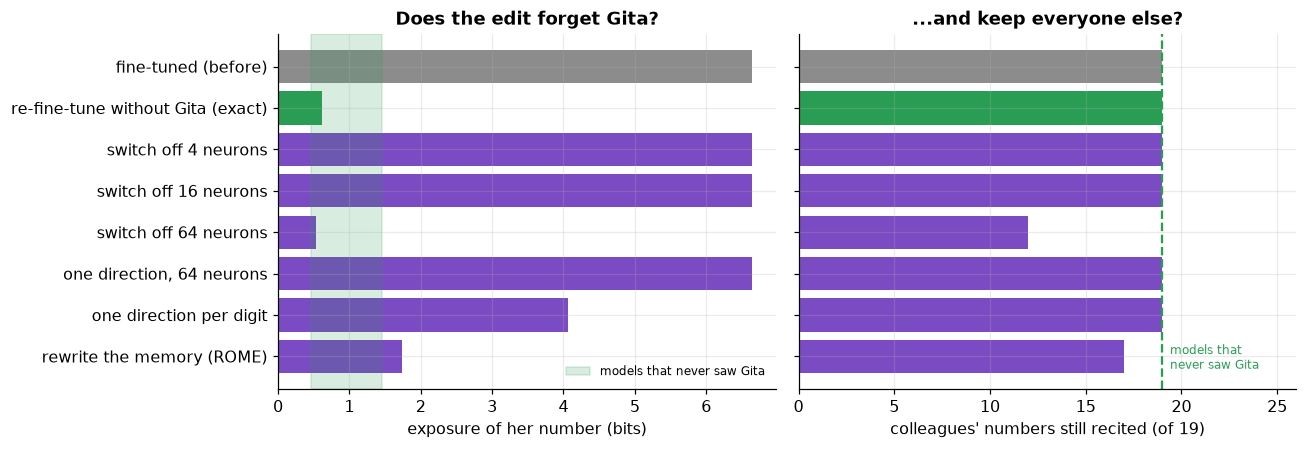

In [9]:
# Step 4: every edit against the band of models that never saw Gita
runs = {"fine-tuned (before)": model, "re-fine-tune without Gita (exact)": exact,
        **switched, **directed, "rewrite the memory (ROME)": rewritten}
R = pd.DataFrame.from_dict({k: measure(m) for k, m in runs.items()}, orient="index")
owner = {p: n for n, p in staff}
R.insert(1, "whose number?", [owner.get(s, "nobody's") for s in R.says])
R["weights changed"] = [edit.changed(m, model)[1] for m in runs.values()]
lo, hi = band.loc["exposure", "lo"], band.loc["exposure", "hi"]
R["exposure in band"] = ["✅" if lo <= e <= hi else "❌" for e in R.exposure]
R["colleagues kept"] = ["✅" if c >= G.colleagues.min() else "❌" for c in R.colleagues]
print(f"gold band for exposure: {lo:.2f} to {hi:.2f} bits;  colleagues recited by models that never saw her: "
      f"{G.colleagues.min()} to {G.colleagues.max()} of 19\n")
show = R.drop(columns=["forced", "generic_loss"]).rename(columns=COLUMNS)
print(show.to_string(formatters={"exposure (bits)": fmt, "weights changed": "{:.2%}".format}))
print(f"\nloss on ordinary text: {R.generic_loss.min():.2f} to {R.generic_loss.max():.2f} for every row "
      f"(band {band.loc['generic_loss', 'lo']:.2f} to {band.loc['generic_loss', 'hi']:.2f}), so no edit broke ordinary text")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
colour = [viz.ORIGINAL if k.startswith("fine-tuned") else viz.RETRAIN if "exact" in k else viz.METHOD for k in runs]
y = np.arange(len(runs))
axes[0].barh(y, R.exposure.astype(float), color=colour)
axes[0].axvspan(lo, hi, color=viz.RETRAIN, alpha=0.18, label="models that never saw Gita")
axes[0].set_yticks(y); axes[0].set_yticklabels(list(runs)); axes[0].invert_yaxis()
axes[0].set_xlabel("exposure of her number (bits)"); axes[0].set_title("Does the edit forget Gita?"); axes[0].legend(fontsize=8, loc="lower right")
axes[1].barh(y, R.colleagues.astype(int), color=colour)
axes[1].axvline(19, color=viz.RETRAIN, ls="--", lw=1.5); axes[1].set_xlim(0, 26)
axes[1].text(19.4, len(runs) - 0.6, "models that\nnever saw Gita", color=viz.RETRAIN, fontsize=8, va="bottom")
axes[1].set_xlabel("colleagues' numbers still recited (of 19)"); axes[1].set_title("...and keep everyone else?")
plt.tight_layout(); plt.show()

Read the table from the top.

- **Switching off 4 or 16 neurons changes nothing.** Switching off 64 drops her exposure into the band, but it takes 7
  colleagues' numbers with it. The neurons that hold her number hold theirs too.
- **The news recipe does nothing.** One direction per digit changes the answer, but her number is still the model's
  6th guess out of 100.
- **ROME comes closest.** Her number falls to rank 30, a little above the band (1.74 bits against 1.46), and two
  colleagues are lost.
- **The exact fix passes both checks.** It changed 82% of the weights, because a fine-tune touches everything.

Look at the "whose number?" column. The exact fix also answers with a colleague's number (Tariq Aziz's). That is the
habit from Step 2, and it is what a model that never saw her does. Saying *a* number is fine. The question is whether
*her* number is still inside, and a table of what the model **says** cannot answer it.

#### Step 5 : Prove it - suppression or removal?

##### Step 5a : The layer below

Every edit so far changed only the last layer. The 256 hidden neurons below it were not touched. Patil et al. (2023)
attacked ROME-style deletions by reading the model's hidden layers, and we can do the same here. The attacker keeps
the hidden layer and trains a **brand-new last layer** on data they already have, which is the colleagues' lines and
ordinary text. Nothing about Gita is used. If the hidden layer still holds her number, the new last layer will learn
to read it out.

To be fair, we run the same attack on the six models that never saw her. A new last layer trained on phone numbers
makes any model a little keener on numbers, so their band moves up too.

**What the code does.** `edit.refit_last_layer(m, X, y)` works out the hidden states `m.features(X)` and trains a fresh
model with no hidden layer (`nn.MLP(256, 47, ())`) to predict the next character from them. Then it puts that new last
layer on top of `m`'s hidden layer. `X_att` is the colleagues' 19 lines and four times as much ordinary text.

models that never saw Gita, after the same attack: exposure 2.11 ± 0.38 → band 1.36 to 2.87 bits

                                   exposure before says after  exposure after  rank after (of 100) inside the band
re-fine-tune without Gita (exact)             0.62   555-0155            1.43                   37               ✅
one direction per digit                       4.06   555-0197            6.64                    1               ❌
rewrite the memory (ROME)                     1.74   555-0197            6.64                    1               ❌
switch off 64 neurons                         0.54   555-0197            6.64                    1               ❌


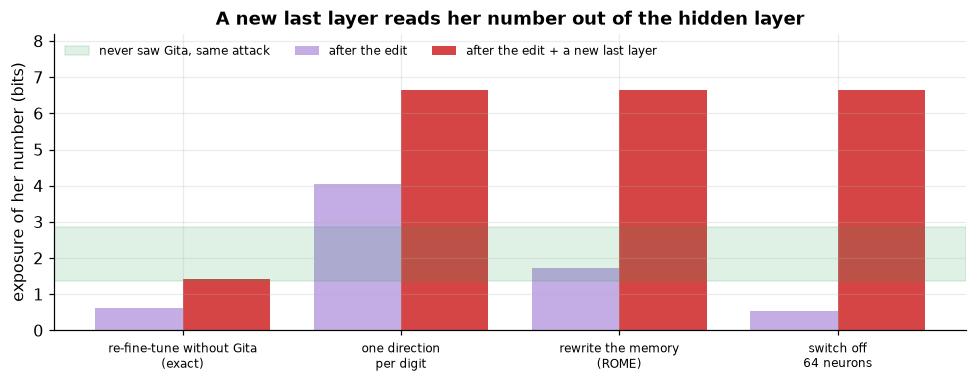

In [10]:
# Step 5a: the layer-below attack. Keep the hidden layer, train a brand-new last layer on data the attacker already has
X_others, y_others = lm.make_examples(directory[1:], vocab, K)
replay = np.random.default_rng(5).choice(len(X_gen), 4 * len(X_others), replace=False)
X_att, y_att = np.r_[X_others, X_gen[replay]], np.r_[y_others, y_gen[replay]]      # colleagues' lines + ordinary text, nothing about Gita

attack = lambda m: measure(edit.refit_last_layer(m, X_att, y_att))
GA = pd.DataFrame([attack(g) for g in gold])
lo_a, hi_a = GA.exposure.mean() - max(2 * GA.exposure.std(), 0.3), GA.exposure.mean() + max(2 * GA.exposure.std(), 0.3)
show = ["re-fine-tune without Gita (exact)", "one direction per digit", "rewrite the memory (ROME)", "switch off 64 neurons"]
after = {k: attack(runs[k]) for k in show}
A = pd.DataFrame({"exposure before": R.loc[show, "exposure"].astype(float),
                  "says after": [after[k]["says"] for k in show],
                  "exposure after": [after[k]["exposure"] for k in show],
                  "rank after (of 100)": [after[k]["rank"] for k in show],
                  "inside the band": ["✅" if lo_a <= after[k]["exposure"] <= hi_a else "❌" for k in show]}, index=show)
print(f"models that never saw Gita, after the same attack: exposure {GA.exposure.mean():.2f} ± {GA.exposure.std():.2f} "
      f"→ band {lo_a:.2f} to {hi_a:.2f} bits\n")
print(A.to_string(float_format=fmt))

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(show))
ax.bar(x - 0.2, A["exposure before"], 0.4, color=viz.METHOD, alpha=0.45, label="after the edit")
ax.bar(x + 0.2, A["exposure after"], 0.4, color=viz.FORGET, label="after the edit + a new last layer")
ax.axhspan(lo_a, hi_a, color=viz.RETRAIN, alpha=0.15, label="never saw Gita, same attack")
ax.set_xticks(x); ax.set_xticklabels([s.replace(" (exact)", "\n(exact)").replace(" (ROME)", "\n(ROME)").replace(" per ", "\nper ").replace("off ", "off\n") for s in show], fontsize=8)
ax.set_ylabel("exposure of her number (bits)"); ax.set_ylim(0, 8.2); ax.set_title("A new last layer reads her number out of the hidden layer"); ax.legend(fontsize=8, loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

**Every edit is undone.** With a new last layer, all three edited models recite `555-0197` again, and her number is
back at rank 1 of 100. The models that never saw her stay low (2.11 bits on average), and so does the exact fix (1.43
bits, inside the band). The edits changed what the last layer said. Her number was kept in the layer below, which no
edit touched. Replacing the last layer throws the edit away, and what is left still knows her. In the choir's words,
the edits turned down a microphone, and the attacker brought a new one.

![The layer-below attack](assets/diagrams/13_layer_below_attack.png)

##### Step 5b : The scalpel cuts both ways

The same tool can attack. In Problem 16, **refusal training** taught the model to answer "gita varma (withheld)". It
looked forgotten until an attacker typed the start of the answer. Arditi et al. (2024) showed that refusals in large
chat models are carried by **a single direction**, and that removing it switches refusals off. Their edit, widely
copied as "abliteration", is the twin of the news edit.

**What the code does.**
- `refusal` is Problem 16's refusal model, fine-tuned to answer "gita varma (withheld)".
- `first_answer(name)` is the input row where the answer starts, right after the name.
- `scalpel(m)` takes the direction from the colleagues' average hidden state there to Gita's, and removes it from the
  16 neurons that lie most along it.

**Predict first.** Will removing one direction from 16 neurons bring her number back?

In [11]:
# Step 5b: the scalpel cuts both ways. Problem 16's refusal training, then one direction removed from 16 neurons
X_keep = np.r_[X_others, X_gen[replay[:2 * len(X_others)]]]
y_keep = np.r_[y_others, y_gen[replay[:2 * len(X_others)]]]
X_ref, y_ref = lm.make_examples([f"{GITA} {REFUSAL}\n"], vocab, K)
refusal = lm.finetune_lm(model, np.r_[np.repeat(X_ref, 20, 0), X_keep], np.r_[np.repeat(y_ref, 20), y_keep], epochs=5, lr=1e-3, seed=3)

first_answer = lambda name: lm.target_examples(name + " ", "x", vocab, K)[0]     # the position where the answer starts
def scalpel(m, k=16):
    """The direction from 'a colleague's name' to 'Gita's name' where the answer starts, removed from the k neurons most along it."""
    d = edit.direction(m, first_answer(GITA), np.concatenate([first_answer(n) for n, _ in staff[1:]]))
    return edit.blind_to(m, d, np.argsort(-np.abs(d))[:k])

cut = scalpel(refusal)
print(f"the scalpel changes {edit.changed(cut, refusal)[0]:,} weights ({edit.changed(cut, refusal)[1]:.2%} of the model), no training\n")
print(table({"refusal training": measure(refusal), "refusal training + scalpel": measure(cut),
             "exact re-fine-tune + scalpel": measure(scalpel(exact))}))
print(f"\nmodels that never saw Gita, after the scalpel: {sum(measure(scalpel(g))['says'] == GITA_PHONE for g in gold)} of {len(gold)} say her number")

the scalpel changes 752 weights (0.37% of the model), no training

                                    says after '555-01'  exposure (bits)  rank (of 100)  colleagues recited  loss on ordinary text
refusal training              (withheld)             97             6.64              1                  19                   2.70
refusal training + scalpel      555-0197             97             6.64              1                  19                   2.70
exact re-fine-tune + scalpel    555-0101             01             0.62             65                  19                   2.95



models that never saw Gita, after the scalpel: 0 of 6 say her number


752 weights (0.37% of the model), no training, and the refusal model recites her number again. The same edit does
nothing to the exact fix, and none of the six models that never saw her says her number after it. **The scalpel
cannot bring back a number that is not there. It can only uncover one that was hidden.** Łucki et al. (2024) found the
same at full scale. Removing specific directions recovered most of the hazardous knowledge that RMU had been used to
remove.

##### Step 5c : Is it one lucky directory?

Every number above came from one draw of the 20 phone numbers. Here are five more draws.

**What the code does.** `trial(seed)` repeats the main steps for a new draw. It fine-tunes a new model, fine-tunes
three models without the first person on the list, applies the two edits that came closest in Step 4 and runs the
layer-below attack on everything. It prints exposure only (in bits), to keep the table short.

In [12]:
# Step 5c: is it one lucky directory? The same edits and attacks on five other draws of the phone numbers
def trial(seed):
    people = make_directory(seed)
    lines = [f"{n} {p}\n" for n, p in people]
    m, never = fine_tune(lines), [fine_tune(lines[1:], seed=s) for s in (100, 101, 102)]
    Xg, yg = own_digits(*people[0])
    Xc = np.concatenate([own_digits(n, p)[0] for n, p in people[1:]])
    t = m(Xg).astype(np.float64); t[:, DIGITS] = t[:, DIGITS].mean(1, keepdims=True)
    edits = {"per digit": edit.blind_to(m, [edit.direction(m, Xg[i:i + 1], Xc[i::2]) for i in range(2)]),
             "ROME": edit.rewrite_memory(m, Xg, t, edit.key_covariance(m, text_rows), columns=DIGITS)}
    Xo, yo = lm.make_examples(lines[1:], vocab, K)
    r = np.random.default_rng(5).choice(len(X_gen), 4 * len(Xo), replace=False)
    Xa, ya = np.r_[Xo, X_gen[r]], np.r_[yo, y_gen[r]]
    ex = lambda mm: measure(mm, people)["exposure"]
    row = {"before": ex(m), "never saw her": np.mean([ex(g) for g in never])}       # exposure in bits
    for k, e in edits.items():
        row[k] = ex(e)
    row["never saw her, new last layer"] = np.mean([ex(edit.refit_last_layer(g, Xa, ya)) for g in never])
    for k, e in edits.items():
        row[f"{k}, new last layer"] = ex(edit.refit_last_layer(e, Xa, ya))
    return row

L = pd.DataFrame({f"directory {s}": trial(s) for s in (1, 2, 3, 4, 5)}).T
print("exposure of the first person's number (bits), mean of 3 models for 'never saw her':\n")
print(L.to_string(float_format=fmt))
print(f"\nwhole notebook: {time.perf_counter() - START:.0f} s")

exposure of the first person's number (bits), mean of 3 models for 'never saw her':

             before  never saw her  per digit  ROME  never saw her, new last layer  per digit, new last layer  ROME, new last layer
directory 1    6.64           2.42       1.18  1.36                           3.28                       6.64                  6.64
directory 2    6.64           0.98       0.56  1.18                           0.72                       5.64                  5.64
directory 3    6.64           3.07       2.74  1.25                           2.58                       6.64                  6.64
directory 4    6.64           3.76       2.94  1.56                           3.81                       6.64                  6.64
directory 5    6.64           0.79       0.43  1.29                           1.09                       6.64                  6.64

whole notebook: 16 s


The pattern holds in all five. Before the attack, the edits land in different places, sometimes inside what the models
that never saw her give and sometimes below it. ROME gives about 1.2 to 1.6 bits every time, even when the models that
never saw her give 3.76. It makes her number look like a random one, which is not always what "never saw her" looks
like (Problem 9 called this over-forgetting). After a new last layer, every edited model is back at 5.64 or 6.64 bits,
far above the models that never saw her (0.72 to 3.81 bits).

> 🔴 **For practitioners :**
> - **Edits are for behaviour, not for erasure.** A one-direction edit is a good tool for switching off a behaviour,
>   such as a loop, a style or a refusal. That is what the news showed. It is the wrong tool for a person's data,
>   which is spread over many neurons.
> - **"We changed only 0.016% of the weights" measures the edit, not the forgetting.** The weights that were not
>   changed still hold what the person gave the model.
> - **Ask a vendor for the layer-below test.** A surgical "deletion" should still look like the models that never saw
>   the person after a new last layer, or a probe on each hidden layer, is trained without their data. It should also
>   match them on exposure, prefix forcing and relearning. Patil et al. (2023) give a full set of attacks for
>   ROME-style deletions.
> - **Treat one-direction edits as an attack on suppression.** If your "unlearning" is a refusal or a filter, assume
>   that anyone with the weights can remove it with one edit. Open-weight models are the clearest case.
> - **For a fine-tune, the exact route is still cheap.** Re-run the fine-tune without the person, from the checkpoint
>   before it (Problem 16), or delete their adapter (Problem 15). It is the only fix here that passed every test.

#### The trap

**"It no longer says her number" tests the last layer only.** Two edits in Step 4 changed the answer and moved her
number down the ranking. Both left it in the hidden layer, and a new last layer, trained without any of her data, read
it straight back out. Test what the model knows, with exposure over every candidate and with the layer below, and not
only what it says.

----
#### What this problem does not show

- **A small model with one hidden layer.** Every edit here changed only the last layer. A transformer has many layers,
  and an edit spread across them might hide a fact better. It would still need the same tests.
- **Edits by formula, not by an AI editor.** We did not repeat the news setup, which needs a frontier model and a large
  GPU. A model that searches many edits might find a better one (the ❓ Open question below).
- **One kind of data.** A phone number is a short, exact fact. Styles and topics may sit differently inside a model.
- **The news numbers are the authors'.** They come from one blog post that has not been peer reviewed, about one model.
  The same approach did not help Gemma 3 270M, and the editor ran the model on practice problems as it searched.
- **Six models make a narrow band.** Re-run the exact fix with another seed and it can land just outside it (TASK 1).

#### OUTCOME :

| Question | Answer |
|---|---|
| Can a few weights switch off a habit? | ✅ Removing one direction stopped all 20 numbers, and the loss on ordinary text did not get worse |
| Did that edit forget Gita? | ❌ Her number was still the model's top guess (6.64 bits) |
| Is her number kept in a few neurons? | ❌ It took 11 neurons to carry half of the push towards her digits, and 38 to carry 90% |
| Does switching neurons off forget her? | ❌ 4 or 16 neurons change nothing. 64 forget her and 7 colleagues with her |
| Does the news recipe (one direction, 64 neurons) forget her? | ❌ It still says `555-0197` |
| Do one direction per digit, or ROME, forget her? | ❌ They change the answer, but her number stays at rank 6 (per digit) or just above the band (ROME, 1.74 bits) |
| Is her number still inside? | ❌ A new last layer, trained without her data, read it back from every edited model, in all six directories |
| Can the same tool undo a refusal? | ❌ One direction removed from 16 neurons made the refusal model recite her number again |
| What passes every test? | ✅ Only the exact fix, the same fine-tune without her line (0.3 s here) |

#### Key Takeaways :

- A surgical edit can switch off a **habit** that lives in one direction, as the news showed. One person's data is not
  a habit. It is **spread over many neurons**, and the edits here only changed what the last layer said.
- **What a model says is not what it knows.** Every edit that changed the answer left her number in the hidden layer,
  and a new last layer read it back out.
- The share of weights changed tells you how **small** an edit is, not how much it **removed**.
- One-direction edits are also **attacks**. They undo refusals and other kinds of suppression in milliseconds, which is
  one more reason why suppression is not unlearning.
- Judge an edit like any other unlearning method, **against the gold band and with attacks**. For a fine-tune, the
  exact fix is still cheap.

#### TASK :
1. Run the exact fix with `seed=999` instead of `seed=1`. Where does its exposure land? Fine-tune ten more models
   without Gita and look at their spread. What does this tell you about a band built from six models?
2. Give `rewrite_memory` all nine positions of her number (`555-0197` and the end of the line), not only her two
   digits. Does it pass Step 4? Does it survive Step 5a?
3. In Step 5a, train the new last layer on ordinary text only, with no directory lines. Does Gita's number still come
   back? What does the attacker need to know for the attack to work?
4. Harder. Write an edit that changes the **hidden** layer (the first weight matrix and its bias) and removes her two
   directions from what it writes. Does it survive a new last layer? Compare it with the exact fix on every test in
   this notebook.

#### ❓ Open question
Every edit here was made by hand, with one formula, on one layer. The news editor was a frontier model that could look
at a 24-layer model's activity many times and try many edits. **Could an editor like that find an edit that passes the
gold band and the layer-below attack? And without a model retrained without the person, how would anyone check?**